In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

pd.DataFrame({
    "ID": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 14],
    "Dept": ["CSE", "AIML", "ECE", "CSE", "AIML"] * 3,
    "Role": ["Dev", "Analyst", "Dev", "Analyst", "Dev"] * 3,
    "Score": [85, 92, 78, np.nan, 88, 95, 72, 81, 90, 84, 76, 89, 93, 87, 87],
    "Salary": [50, 65, 45, 55, 70, 80, 48, 52, 75, 60, 42, 68, 85, 58, 58],
    "Date": pd.date_range("2026-01-01 09:30:00", periods=15, freq="D")
}).to_csv("data.csv", index=False)
print("Master 'data.csv' created.")

Master 'data.csv' created.


In [2]:
df = pd.read_csv("data.csv")
print(df.head())

   ID  Dept     Role  Score  Salary                 Date
0   1   CSE      Dev   85.0      50  2026-01-01 09:30:00
1   2  AIML  Analyst   92.0      65  2026-01-02 09:30:00
2   3   ECE      Dev   78.0      45  2026-01-03 09:30:00
3   4   CSE  Analyst    NaN      55  2026-01-04 09:30:00
4   5  AIML      Dev   88.0      70  2026-01-05 09:30:00


In [3]:
df_np = pd.DataFrame(np.arange(1, 10).reshape(3, 3), columns=["A", "B", "C"])
print(df_np)

   A  B  C
0  1  2  3
1  4  5  6
2  7  8  9


In [4]:
print(df[(df["Dept"] == "CSE") & (df["Salary"] > 50)])

    ID Dept     Role  Score  Salary                 Date
3    4  CSE  Analyst    NaN      55  2026-01-04 09:30:00
5    6  CSE      Dev   95.0      80  2026-01-06 09:30:00
8    9  CSE  Analyst   90.0      75  2026-01-09 09:30:00
13  14  CSE  Analyst   87.0      58  2026-01-14 09:30:00


In [5]:
print("First 7 Rows:\n", df.head(7), "\n\nLast 7 Rows:\n", df.tail(7))

First 7 Rows:
    ID  Dept     Role  Score  Salary                 Date
0   1   CSE      Dev   85.0      50  2026-01-01 09:30:00
1   2  AIML  Analyst   92.0      65  2026-01-02 09:30:00
2   3   ECE      Dev   78.0      45  2026-01-03 09:30:00
3   4   CSE  Analyst    NaN      55  2026-01-04 09:30:00
4   5  AIML      Dev   88.0      70  2026-01-05 09:30:00
5   6   CSE      Dev   95.0      80  2026-01-06 09:30:00
6   7  AIML  Analyst   72.0      48  2026-01-07 09:30:00 

Last 7 Rows:
     ID  Dept     Role  Score  Salary                 Date
8    9   CSE  Analyst   90.0      75  2026-01-09 09:30:00
9   10  AIML      Dev   84.0      60  2026-01-10 09:30:00
10  11   CSE      Dev   76.0      42  2026-01-11 09:30:00
11  12  AIML  Analyst   89.0      68  2026-01-12 09:30:00
12  13   ECE      Dev   93.0      85  2026-01-13 09:30:00
13  14   CSE  Analyst   87.0      58  2026-01-14 09:30:00
14  14  AIML      Dev   87.0      58  2026-01-15 09:30:00


In [6]:
print(df[df["Salary"] >= 65])

    ID  Dept     Role  Score  Salary                 Date
1    2  AIML  Analyst   92.0      65  2026-01-02 09:30:00
4    5  AIML      Dev   88.0      70  2026-01-05 09:30:00
5    6   CSE      Dev   95.0      80  2026-01-06 09:30:00
8    9   CSE  Analyst   90.0      75  2026-01-09 09:30:00
11  12  AIML  Analyst   89.0      68  2026-01-12 09:30:00
12  13   ECE      Dev   93.0      85  2026-01-13 09:30:00


In [7]:
df["Log_Salary"] = np.round(np.log(df["Salary"]), 2)
print(df[["Salary", "Log_Salary"]].head())

   Salary  Log_Salary
0      50        3.91
1      65        4.17
2      45        3.81
3      55        4.01
4      70        4.25


In [8]:
dept_df = pd.DataFrame({"Dept": ["CSE", "AIML", "ECE"], "Block": ["A", "B", "C"]})
print(pd.merge(df[["ID", "Dept", "Salary"]].head(), dept_df, on="Dept"))

   ID  Dept  Salary Block
0   1   CSE      50     A
1   2  AIML      65     B
2   3   ECE      45     C
3   4   CSE      55     A
4   5  AIML      70     B


In [9]:
arr = np.full(len(df), 10)
print((df["Salary"] + arr).head())

0    60
1    75
2    55
3    65
4    80
Name: Salary, dtype: int64


In [10]:
print(np.sqrt(df["Salary"]).round(2).head())

0    7.07
1    8.06
2    6.71
3    7.42
4    8.37
Name: Salary, dtype: float64


In [11]:
print(df.corr(numeric_only=True))

                  ID     Score    Salary  Log_Salary
ID          1.000000  0.082416  0.218183    0.213821
Score       0.082416  1.000000  0.875427    0.890186
Salary      0.218183  0.875427  1.000000    0.995028
Log_Salary  0.213821  0.890186  0.995028    1.000000


In [12]:
df["Cum_Salary"] = np.cumsum(df["Salary"].to_numpy())
print(df[["Salary", "Cum_Salary"]].head())

   Salary  Cum_Salary
0      50          50
1      65         115
2      45         160
3      55         215
4      70         285


In [13]:
print(df.groupby("Dept")["Salary"].mean())

Dept
AIML    61.500000
CSE     60.000000
ECE     60.666667
Name: Salary, dtype: float64


In [14]:
print(df.pivot_table(values="Salary", index="Dept", columns="Role", aggfunc="mean"))

Role    Analyst        Dev
Dept                      
AIML  60.333333  62.666667
CSE   62.666667  57.333333
ECE         NaN  60.666667


In [15]:
df["Score"] = df["Score"].fillna(df["Score"].mean())
print(df[["ID", "Score"]].head(5))

   ID  Score
0   1   85.0
1   2   92.0
2   3   78.0
3   4   85.5
4   5   88.0


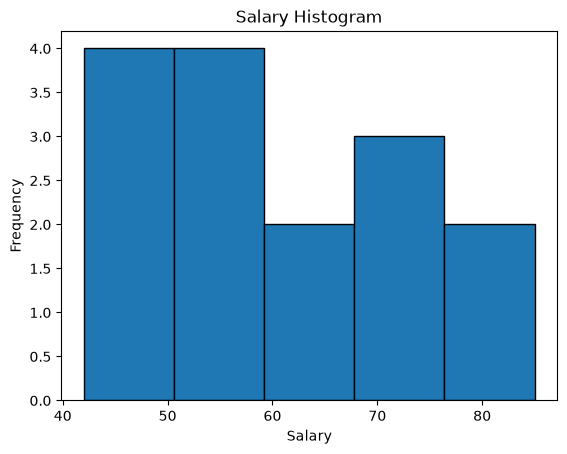

In [16]:
counts, bins = np.histogram(df["Salary"].dropna(), bins=5)
plt.hist(bins[:-1], bins, weights=counts, edgecolor="black")
plt.title("Salary Histogram"); plt.xlabel("Salary"); plt.ylabel("Frequency"); plt.show()

In [17]:
df["Norm_Salary"] = (df["Salary"] - df["Salary"].min()) / (df["Salary"].max() - df["Salary"].min())
print(df[["Salary", "Norm_Salary"]].head())

   Salary  Norm_Salary
0      50     0.186047
1      65     0.534884
2      45     0.069767
3      55     0.302326
4      70     0.651163


In [18]:
df = df.drop_duplicates()
print(f"Total rows after removing duplicates: {len(df)}\n", df.tail(3))

Total rows after removing duplicates: 15
     ID  Dept     Role  Score  Salary                 Date  Log_Salary  \
12  13   ECE      Dev   93.0      85  2026-01-13 09:30:00        4.44   
13  14   CSE  Analyst   87.0      58  2026-01-14 09:30:00        4.06   
14  14  AIML      Dev   87.0      58  2026-01-15 09:30:00        4.06   

    Cum_Salary  Norm_Salary  
12         795     1.000000  
13         853     0.372093  
14         911     0.372093  


In [19]:
print(df.sort_values(by="Salary", ascending=False).head())

    ID  Dept     Role  Score  Salary                 Date  Log_Salary  \
12  13   ECE      Dev   93.0      85  2026-01-13 09:30:00        4.44   
5    6   CSE      Dev   95.0      80  2026-01-06 09:30:00        4.38   
8    9   CSE  Analyst   90.0      75  2026-01-09 09:30:00        4.32   
4    5  AIML      Dev   88.0      70  2026-01-05 09:30:00        4.25   
11  12  AIML  Analyst   89.0      68  2026-01-12 09:30:00        4.22   

    Cum_Salary  Norm_Salary  
12         795     1.000000  
5          365     0.883721  
8          540     0.767442  
4          285     0.651163  
11         710     0.604651  


In [20]:
print(df[["Salary", "Score"]].map(lambda x: round(x * 1.1, 1)).head())

   Salary  Score
0    55.0   93.5
1    71.5  101.2
2    49.5   85.8
3    60.5   94.1
4    77.0   96.8


In [21]:
print(df.rename(columns={"Dept": "Department", "Salary": "Pay"}).head(3))

   ID Department     Role  Score  Pay                 Date  Log_Salary  \
0   1        CSE      Dev   85.0   50  2026-01-01 09:30:00        3.91   
1   2       AIML  Analyst   92.0   65  2026-01-02 09:30:00        4.17   
2   3        ECE      Dev   78.0   45  2026-01-03 09:30:00        3.81   

   Cum_Salary  Norm_Salary  
0          50     0.186047  
1         115     0.534884  
2         160     0.069767  


In [22]:
df_transposed = df.head(3).T
print(df_transposed)

                               0                    1                    2
ID                             1                    2                    3
Dept                         CSE                 AIML                  ECE
Role                         Dev              Analyst                  Dev
Score                       85.0                 92.0                 78.0
Salary                        50                   65                   45
Date         2026-01-01 09:30:00  2026-01-02 09:30:00  2026-01-03 09:30:00
Log_Salary                  3.91                 4.17                 3.81
Cum_Salary                    50                  115                  160
Norm_Salary             0.186047             0.534884             0.069767


In [23]:
targets = pd.DataFrame({"Dept": ["CSE", "AIML"], "Role": ["Dev", "Analyst"], "Target": [90, 95]})
print(pd.merge(df[["ID", "Dept", "Role", "Score"]], targets, on=["Dept", "Role"]))

   ID  Dept     Role  Score  Target
0   1   CSE      Dev   85.0      90
1   2  AIML  Analyst   92.0      95
2   6   CSE      Dev   95.0      90
3   7  AIML  Analyst   72.0      95
4  11   CSE      Dev   76.0      90
5  12  AIML  Analyst   89.0      95


In [24]:
print(df.groupby("Dept")["Salary"].agg(["mean", "min", "max", "sum"]))

           mean  min  max  sum
Dept                          
AIML  61.500000   48   70  369
CSE   60.000000   42   80  360
ECE   60.666667   45   85  182


In [25]:
dt = pd.to_datetime(df["Date"])
print(pd.DataFrame({"Date": dt.dt.date, "Time": dt.dt.time, "Year": dt.dt.year, "Month": dt.dt.month}).head())

         Date      Time  Year  Month
0  2026-01-01  09:30:00  2026      1
1  2026-01-02  09:30:00  2026      1
2  2026-01-03  09:30:00  2026      1
3  2026-01-04  09:30:00  2026      1
4  2026-01-05  09:30:00  2026      1


In [26]:
ts = df.assign(Date=pd.to_datetime(df["Date"])).set_index("Date")
print(ts["Salary"].resample("3D").mean())

Date
2026-01-01    53.333333
2026-01-04    68.333333
2026-01-07    58.333333
2026-01-10    56.666667
2026-01-13    67.000000
Freq: 3D, Name: Salary, dtype: float64


In [27]:
df["Rolling_Mean"] = df["Salary"].rolling(window=3).mean()
print(df[["Salary", "Rolling_Mean"]].head(5))

   Salary  Rolling_Mean
0      50           NaN
1      65           NaN
2      45     53.333333
3      55     55.000000
4      70     56.666667


In [28]:
print(pd.crosstab(df["Dept"], df["Role"]))

Role  Analyst  Dev
Dept              
AIML        3    3
CSE         3    3
ECE         0    3
